In [1]:

!pip -q install tensorflow-datasets

import tensorflow_datasets as tfds

builder = tfds.builder("so2sat/rgb")

print("Dataset:", builder.info.name)
print("Version:", builder.info.version)
print("Features:", builder.info.features)
print("Splits:", builder.info.splits)


Dataset: so2sat
Version: 2.1.0
Features: FeaturesDict({
    'image': Image(shape=(32, 32, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=17),
    'sample_id': int64,
})
Splits: {}


In [3]:

!pip install -q importlib_resources


In [4]:

import tensorflow_datasets as tfds

builder = tfds.builder("so2sat")

builder.download_and_prepare()

print("Available splits:", builder.info.splits)
print("Dataset size:", builder.info)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

KeyboardInterrupt: 

In [5]:
import os
import shutil

print("Disk usage:")
print(shutil.disk_usage("/"))

for folder in [
    "/root/tensorflow_datasets/downloads",
    "/root/tensorflow_datasets/so2sat"
]:
    if os.path.exists(folder):
        print(f"\n{folder}")
        print("Size:", sum(
            os.path.getsize(os.path.join(root, f))
            for root, _, files in os.walk(folder)
            for f in files
        ) / (1024**3), "GB")

Disk usage:
usage(total=115658190848, used=55663132672, free=59978280960)

/root/tensorflow_datasets/downloads
Size: 51.75003641564399 GB

/root/tensorflow_datasets/so2sat
Size: 2.7939677238464355e-08 GB


In [6]:

!wget -q https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation_geo.h5
!wget -q https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/testing_geo.h5

print("Geographic metadata downloaded.")


Geographic metadata downloaded.


In [7]:

import h5py
import numpy as np

for filename in ["validation_geo.h5", "testing_geo.h5"]:
    print("\n", filename)

    with h5py.File(filename, "r") as f:
        print("Keys:", list(f.keys()))

        cities = f["city"][:]
        unique_cities, counts = np.unique(cities, return_counts=True)

        print("Number of patches:", len(cities))
        print("Cities:")
        for city, count in zip(unique_cities, counts):
            print(city.decode() if isinstance(city, bytes) else city, count)



 validation_geo.h5
Keys: ['city', 'epsg', 'tfw']
Number of patches: 24119
Cities:
guangzhou 2413
jakarta 2411
moscow 2411
mumbai 2413
munich 2412
nairobi 2411
sanfrancisco 2413
santiago 2413
sydney 2411
tehran 2411

 testing_geo.h5
Keys: ['city', 'epsg', 'tfw']
Number of patches: 24188
Cities:
guangzhou 2420
jakarta 2420
moscow 2420
mumbai 2421
munich 2420
nairobi 2417
sanfrancisco 2417
santiago 2418
sydney 2419
tehran 2416


In [8]:

!wget -c https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation.h5.gz


--2026-11-14 16:03:29--  https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation.h5.gz
Resolving huggingface.co (huggingface.co)... 3.170.185.33, 3.170.185.35, 3.170.185.25, ...
Connecting to huggingface.co (huggingface.co)|3.170.185.33|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/69208ed98b52b78584c81df4/aea18f89ed07fd469a4bafbea4773e93496c255362ea9fdbdf8e00b475b37776?user_id=public&response-content-type=application%2Fgzip&X-Xet-Cas-Uid=public&xip=PzjyuGbsVw0&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27validation.h5.gz%3B+filename%3D%22validation.h5.gz%22%3B&Expires=1794675809&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjkyMDhlZDk4YjUyYjc4NTg0YzgxZGY0L2FlYTE4Zjg5ZWQwN2ZkNDY5YTRiYWZiZWE0NzczZTkzNDk2YzI1NTM2MmVhOWZkYmRmOGUwMGI0NzViMzc3NzZcXD91c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LXR5cGU9KiZYLVhldC1DYXMtVWlkPXB1YmxpYyZ4

In [9]:
import gzip
import os

file_path = "/content/validation.h5.gz"

print("File exists:", os.path.exists(file_path))
print("File size (GB):", os.path.getsize(file_path) / 1e9)

File exists: True
File size (GB): 1.100208338


In [10]:
import gzip
import h5py
import os

file_path = "/content/validation.h5.gz"

with gzip.open(file_path, "rb") as gz:
    with open("/content/validation.h5", "wb") as out:
        while chunk := gz.read(1024 * 1024):
            out.write(chunk)

with h5py.File("/content/validation.h5", "r") as f:
    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(name, obj.shape, obj.dtype)

    f.visititems(inspect)


label (24119, 17) float64
sen1 (24119, 32, 32, 8) float64
sen2 (24119, 32, 32, 10) float64


Number of samples: 24119
Number of classes: 17

Samples per class:
Class 0: 256
Class 1: 1254
Class 2: 2353
Class 3: 849
Class 4: 757
Class 5: 1906
Class 6: 474
Class 7: 3395
Class 8: 1914
Class 9: 860
Class 10: 2287
Class 11: 382
Class 12: 1202
Class 13: 2747
Class 14: 202
Class 15: 672
Class 16: 2609

Sentinel-2 sample:
Shape: (32, 32, 10)
Minimum: 0.0138
Maximum: 0.1216
Mean: 0.05735187500000001


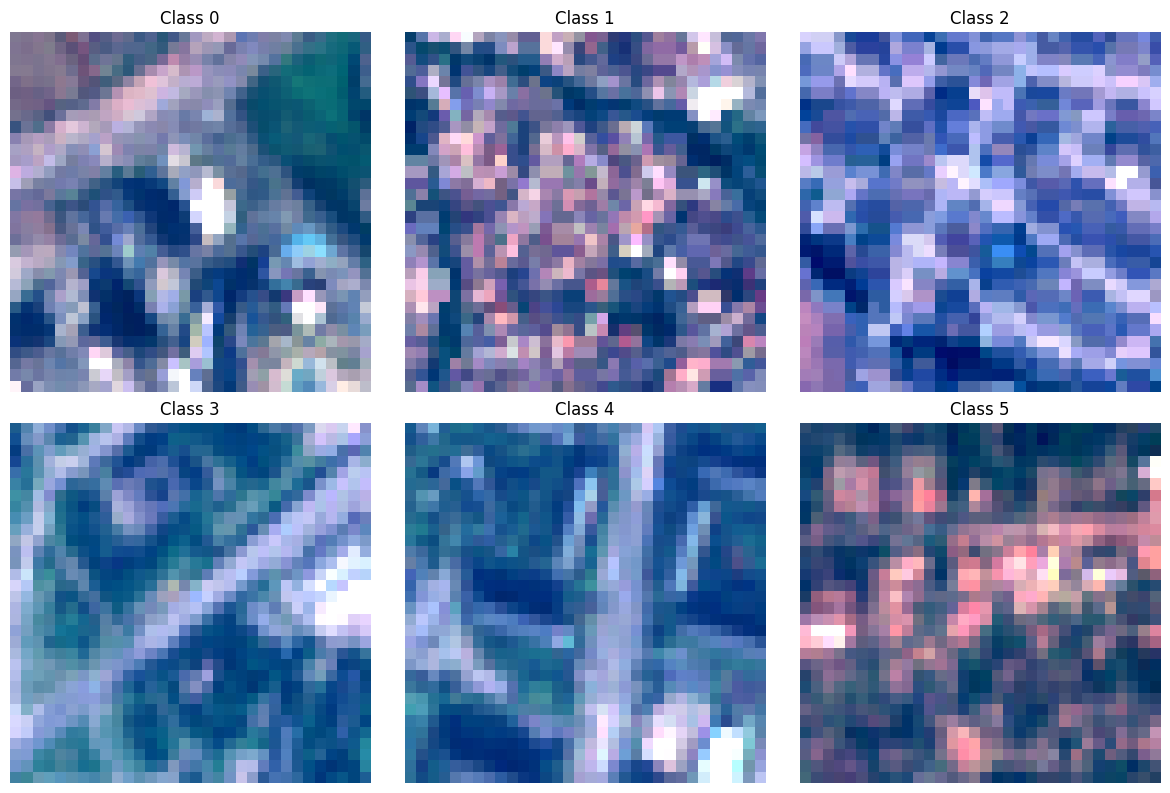

In [11]:

import h5py
import numpy as np
import matplotlib.pyplot as plt

path = "/content/validation.h5"

with h5py.File(path, "r") as f:
    labels = f["label"][:]
    sen2 = f["sen2"]

    # Convert one-hot labels into class indices
    class_ids = np.argmax(labels, axis=1)

    print("Number of samples:", len(class_ids))
    print("Number of classes:", labels.shape[1])
    print("\nSamples per class:")

    for class_id, count in enumerate(np.bincount(class_ids, minlength=17)):
        print(f"Class {class_id}: {count}")

    # Inspect reflectance values
    sample = sen2[0]

    print("\nSentinel-2 sample:")
    print("Shape:", sample.shape)
    print("Minimum:", sample.min())
    print("Maximum:", sample.max())
    print("Mean:", sample.mean())

    # Select one sample from several classes
    selected_classes = np.unique(class_ids)[:6]

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for ax, class_id in zip(axes.flat, selected_classes):
        idx = np.where(class_ids == class_id)[0][0]

        # B4, B3, B2 = RGB
        rgb = sen2[idx][:, :, [2, 1, 0]]

        low = np.percentile(rgb, 2)
        high = np.percentile(rgb, 98)
        rgb = np.clip((rgb - low) / (high - low + 1e-8), 0, 1)

        ax.imshow(rgb)
        ax.set_title(f"Class {class_id}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [12]:
import h5py
import numpy as np

path = "/content/validation.h5"

rng = np.random.default_rng(42)
indices = np.sort(rng.choice(24119, size=500, replace=False))

with h5py.File(path, "r") as f:
    rgb_samples = f["sen2"][indices][:, :, :, [2, 1, 0]]

print("RGB shape:", rgb_samples.shape)

for percentile in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
    print(
        f"{percentile}th percentile:",
        np.percentile(rgb_samples, percentile)
    )

RGB shape: (500, 32, 32, 3)
0th percentile: 0.0001
1th percentile: 0.0298
5th percentile: 0.0516
25th percentile: 0.0885
50th percentile: 0.1142
75th percentile: 0.1389
95th percentile: 0.1897
99th percentile: 0.282
100th percentile: 2.5556


In [13]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][indices][:, :, :, [2, 1, 0]]

for channel, name in enumerate(["Red (B4)", "Green (B3)", "Blue (B2)"]):
    values = rgb[..., channel].ravel()

    print(f"\n{name}")
    for p in [50, 90, 95, 99, 99.5, 99.9, 99.99, 100]:
        print(f"{p}%: {np.percentile(values, p):.5f}")

    print("Values > 0.5:", np.sum(values > 0.5))
    print("Values > 1.0:", np.sum(values > 1.0))



Red (B4)
50%: 0.10250
90%: 0.17530
95%: 0.20060
99%: 0.30500
99.5%: 0.37820
99.9%: 0.50590
99.99%: 0.56750
100%: 0.99220
Values > 0.5: 619
Values > 1.0: 0

Green (B3)
50%: 0.11040
90%: 0.15770
95%: 0.17990
99%: 0.27390
99.5%: 0.33730
99.9%: 0.44910
99.99%: 0.54846
100%: 0.97060
Values > 0.5: 132
Values > 1.0: 0

Blue (B2)
50%: 0.12260
90%: 0.16620
95%: 0.18560
99%: 0.27090
99.5%: 0.32790
99.9%: 0.42750
99.99%: 0.92382
100%: 2.55560
Values > 0.5: 128
Values > 1.0: 50


In [15]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][indices][:, :, :, [2, 1, 0]]

for channel, name in enumerate(["Red", "Green", "Blue"]):
    values = rgb[..., channel]

    flat_idx = np.argmax(values)
    sample_idx, row, col = np.unravel_index(
        flat_idx, values.shape
    )

    print(f"\n{name}")
    print("Maximum:", values[sample_idx, row, col])
    print("Original dataset index:", indices[sample_idx])
    print("Pixel coordinates:", (row, col))
    print("All channel values at same pixel:",
          rgb[sample_idx, row, col, :])


Red
Maximum: 0.9922
Original dataset index: 17383
Pixel coordinates: (np.int64(25), np.int64(13))
All channel values at same pixel: [0.9922 0.9706 0.7422]

Green
Maximum: 0.9706
Original dataset index: 17383
Pixel coordinates: (np.int64(25), np.int64(13))
All channel values at same pixel: [0.9922 0.9706 0.7422]

Blue
Maximum: 2.5556
Original dataset index: 19696
Pixel coordinates: (np.int64(8), np.int64(4))
All channel values at same pixel: [0.1232 0.471  2.5556]


In [16]:
import h5py
import numpy as np

sample_ids = [17383, 19696]

with h5py.File("/content/validation.h5", "r") as f:
    for idx in sample_ids:
        rgb = f["sen2"][idx][:, :, [2, 1, 0]]

        print(f"\nPatch {idx}")
        print("Channel maxima:", rgb.max(axis=(0, 1)))
        print("Channel means:", rgb.mean(axis=(0, 1)))

        # Inspect the 3x3 neighborhood around the blue maximum
        if idx == 19696:
            r, c = 8, 4
            print("Blue-channel neighborhood:")
            print(rgb[r-1:r+2, c-1:c+2, 2])


Patch 17383
Channel maxima: [0.9922 0.9706 0.7422]
Channel means: [0.08817666 0.09237061 0.10486689]

Patch 19696
Channel maxima: [0.3048 0.471  2.5556]
Channel means: [0.09896016 0.10380117 0.12474443]
Blue-channel neighborhood:
[[5.9380e-01 1.1397e+00 2.6590e-01]
 [1.1404e+00 2.5556e+00 9.2580e-01]
 [1.0000e-04 3.8940e-01 3.5140e-01]]


In [17]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    sen2 = f["sen2"]

    thresholds = [0.5, 1.0, 1.5, 2.0]

    counts = {t: 0 for t in thresholds}
    patches_with_extreme = set()

    for start in range(0, len(sen2), 500):
        batch = sen2[start:start+500, :, :, 0]  # B2

        for t in thresholds:
            counts[t] += np.sum(batch > t)

        patch_max = batch.max(axis=(1, 2))
        patches_with_extreme.update(
            (start + np.where(patch_max > 1.0)[0]).tolist()
        )

print("Blue-channel pixel counts:")
for threshold, count in counts.items():
    print(f"> {threshold}: {count:,}")

print("\nPatches with at least one blue value > 1.0:",
      len(patches_with_extreme))

Blue-channel pixel counts:
> 0.5: 4,367
> 1.0: 356
> 1.5: 176
> 2.0: 76

Patches with at least one blue value > 1.0: 47


In [18]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    sen2 = f["sen2"]

    band_names = [
        "B2", "B3", "B4", "B5", "B6",
        "B7", "B8", "B8A", "B11", "B12"
    ]

    band_maxima = np.zeros(10)

    for start in range(0, len(sen2), 500):
        batch = sen2[start:start+500]
        band_maxima = np.maximum(
            band_maxima,
            batch.max(axis=(0, 1, 2))
        )

    for name, maximum in zip(band_names, band_maxima):
        print(f"{name}: {maximum:.4f}")

B2: 2.8000
B3: 2.8000
B4: 2.8000
B5: 2.4563
B6: 2.7932
B7: 2.8002
B8: 2.8000
B8A: 2.8005
B11: 2.4939
B12: 2.1559


In [20]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    # Read B2, B3, B4 in increasing index order
    rgb = f["sen2"][:500, :, :, :3]

    # Reorder B2, B3, B4 into B4, B3, B2
    rgb = rgb[:, :, :, ::-1].copy()

rgb_scaled = np.clip(rgb, 0, 2.8) / 2.8

print("Original range:", rgb.min(), rgb.max())
print("Scaled range:", rgb_scaled.min(), rgb_scaled.max())
print("Scaled mean:", rgb_scaled.mean())
print("Scaled standard deviation:", rgb_scaled.std())

Original range: 0.0001 2.8
Scaled range: 3.571428571428572e-05 1.0
Scaled mean: 0.043128346144903275
Scaled standard deviation: 0.018981059278405737
